# EfficientNet-B7 with CLAHE preprocessing (proposed model)

Fine-tunes an ImageNet-pretrained EfficientNet-B7 on 21 PlantVillage classes. The dataset
was balanced beforehand with CycleGAN-generated images (see the README).

**Pipeline:** CLAHE on every image (L channel of LAB, clip limit 3.0, 8×8 tiles) → resize to
224×224 → normalise to [-1, 1] → 70/15/15 random split → AdamW (lr 1e-3, weight decay 0.01) →
early stopping on validation accuracy (patience 10).

**Result:** 99.35% test accuracy (5,539 images).

> ⚠️ **Evaluation caveat.** The CycleGAN images were added to the class folders *before*
> `random_split`, so the validation and test sets contain generated images as well as real
> ones. See *Evaluation caveats* in the README, and `scripts/make_splits.py` for a
> leakage-free split.

Originally run on Google Colab with a GPU. The `!gdown` / `!unzip` cells download the
prepared dataset from Google Drive.


#proposed model(EfficientNet-B7)


In [ ]:
!pip install efficientnet-pytorch

In [ ]:
!pip install --upgrade sympy

In [ ]:
!pip install torch torchvision matplotlib

In [4]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import torch.optim as optim
from torchvision import models
import torch.nn as nn
import time
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from efficientnet_pytorch import EfficientNet

import torchvision.transforms as transforms
import matplotlib.pyplot as plt


In [ ]:
!gdown --id 1r4LvjGBfe0Fhl4Vqsn8fOrtkH-IaqXaa

In [ ]:
!unzip /content/data.zip -d /content/plantvillage_original

In [ ]:
!unzip /content/data.zip -d /content/plantvillage_dataset

In [ ]:
data_dir = '/content/plantvillage_dataset/content/PlantData/PlantVillage-Dataset/raw/color'


In [ ]:
data_org = '/content/plantvillage_original/content/PlantData/PlantVillage-Dataset/raw/color'


In [ ]:
class_counts = []

for class_name in os.listdir(data_org):
    class_path = os.path.join(data_org, class_name)

    if os.path.isdir(class_path):
        num_images = len(os.listdir(class_path))
        class_counts.append((class_name, num_images))

df_class_counts = pd.DataFrame(class_counts, columns=['Class Name', 'Number of Images'])

df_class_counts.sort_values(by='Class Name', inplace=True)



df_class_counts.reset_index(drop=True, inplace=True)

print(df_class_counts)

                                       Class Name  Number of Images
0                              Apple___Apple_scab              1646
1                               Apple___Black_rot              1646
2                        Apple___Cedar_apple_rust              1646
3                                 Apple___healthy              1645
4                             Blueberry___healthy              1502
5                               Grape___Black_rot              1610
6                                 Grape___healthy              1260
7        Orange___Haunglongbing_(Citrus_greening)              2000
8                          Peach___Bacterial_spot              2000
9                                 Peach___healthy              1688
10                  Pepper,_bell___Bacterial_spot              1998
11                         Pepper,_bell___healthy              1478
12                              Soybean___healthy              2000
13                        Squash___Powdery_milde

In [ ]:
# Function to delete desktop.ini files
def delete_desktop_ini_files(directory):
    for root, dirs, files in os.walk(directory):
        for file in files:
            if file.lower() == 'desktop.ini':
                file_path = os.path.join(root, file)
                try:
                    os.remove(file_path)
                    print(f"Deleted: {file_path}")
                except Exception as e:
                    print(f"Error deleting {file_path}: {e}")

# Call the function
delete_desktop_ini_files(data_dir)

print("Deletion of desktop.ini files completed.")

Deleted: /content/plantvillage_dataset/content/PlantData/PlantVillage-Dataset/raw/color/Apple___Apple_scab/desktop.ini
Deleted: /content/plantvillage_dataset/content/PlantData/PlantVillage-Dataset/raw/color/Apple___Cedar_apple_rust/desktop.ini
Deleted: /content/plantvillage_dataset/content/PlantData/PlantVillage-Dataset/raw/color/Pepper,_bell___Bacterial_spot/desktop.ini
Deleted: /content/plantvillage_dataset/content/PlantData/PlantVillage-Dataset/raw/color/Tomato___Target_Spot/desktop.ini
Deleted: /content/plantvillage_dataset/content/PlantData/PlantVillage-Dataset/raw/color/Apple___Black_rot/desktop.ini
Deletion of desktop.ini files completed.


In [ ]:
def apply_clahe(image):
    img_array = np.array(image)

    lab = cv2.cvtColor(img_array, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)

    limg = cv2.merge((cl, a, b))

    img_output = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

    return Image.fromarray(img_output)

def preprocess_dataset(data_dir):
    for class_name in os.listdir(data_dir):
        class_dir = os.path.join(data_dir, class_name)
        for img_name in os.listdir(class_dir):
            img_path = os.path.join(class_dir, img_name)
            image = Image.open(img_path)

            processed_image = apply_clahe(image)

            processed_image.save(img_path)
preprocess_dataset(data_dir)

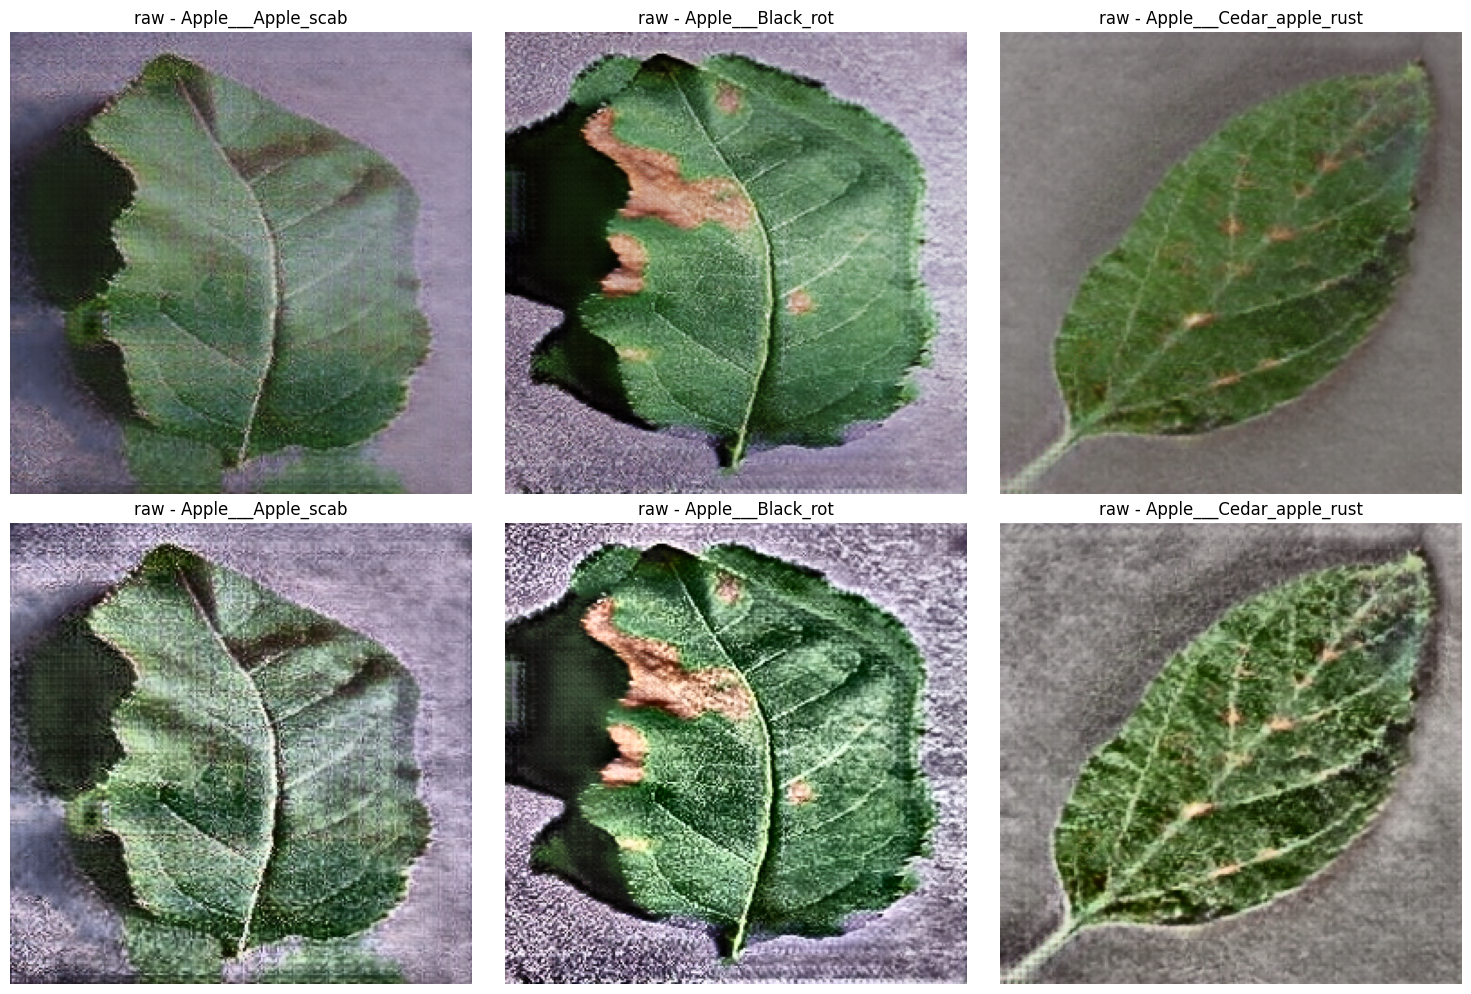

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

classes_to_display = [
    'Apple___Apple_scab',
    'Apple___Black_rot',
    'Apple___Cedar_apple_rust'
]
datasets = [
    '/content/plantvillage_original/content/PlantData/PlantVillage-Dataset/raw/color',
    '/content/plantvillage_dataset/content/PlantData/PlantVillage-Dataset/raw/color'
]

plt.figure(figsize=(15, 10))
for dataset_index, data_org in enumerate(datasets):
    for i, class_name in enumerate(classes_to_display):
        class_path = os.path.join(data_org, class_name)
        images = os.listdir(class_path)
        first_image_path = os.path.join(class_path, images[2])
        image = cv2.imread(first_image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        subplot_position = dataset_index * len(classes_to_display) + i + 1
        plt.subplot(len(datasets), len(classes_to_display), subplot_position)
        plt.imshow(image)
        plt.title(f"{data_org.split('/')[-2]} - {class_name}")
        plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

dataset = datasets.ImageFolder(root=data_dir, transform=transform)

train_size = int(0.7 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(dataset, [train_size, val_size, test_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

for images, labels in train_loader:
    print(images.shape)
    print(labels)
    break

torch.Size([32, 3, 224, 224])
tensor([ 1, 20, 14, 15, 13, 17, 14,  4, 19,  6, 15, 16,  2, 19, 18, 20, 19,  0,
        13,  4,  3, 10, 14,  9, 15, 18, 12,  6,  9, 12, 13, 20])


In [ ]:
model = EfficientNet.from_pretrained('efficientnet-b7')


num_classes = 21
model._fc = nn.Linear(model._fc.in_features, num_classes)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

Loaded pretrained weights for efficientnet-b7


In [ ]:
criterion = nn.CrossEntropyLoss()
#optimizer = optim.Adam(model.parameters(), lr=0.001)
optimizer= optim.AdamW(model.parameters(), lr=0.001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0.01, amsgrad=True)

In [ ]:
train_accuracies = []
val_accuracies = []
epoch_times = []
num_epochs = 100
best_val_accuracy = 0.0

for epoch in range(num_epochs):
    start_time = time.time()

    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct_train / total_train
    train_accuracies.append(train_accuracy)

    model.eval()
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct_val / total_val
    val_accuracies.append(val_accuracy)

    end_time = time.time()
    epoch_time = end_time - start_time
    epoch_times.append(epoch_time)

    print(f'Epoch [{epoch+1}/{num_epochs}], '
          f'Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%')
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        counter = 0
        torch.save(model.state_dict(), 'best_model.pth')
        print("Model checkpoint saved.")
    else:
        counter += 1

    if counter >= 10:
        print("Early stopping done.")
        break

Epoch [1/100], Train Loss: 0.2264, Train Accuracy: 93.24%, Val Loss: 0.1597, Val Accuracy: 94.82%
Model checkpoint saved.
Epoch [2/100], Train Loss: 0.0832, Train Accuracy: 97.26%, Val Loss: 0.0608, Val Accuracy: 98.19%
Model checkpoint saved.
Epoch [3/100], Train Loss: 0.0525, Train Accuracy: 98.24%, Val Loss: 0.0676, Val Accuracy: 97.87%
Epoch [4/100], Train Loss: 0.0439, Train Accuracy: 98.61%, Val Loss: 0.0859, Val Accuracy: 97.44%
Epoch [5/100], Train Loss: 0.0319, Train Accuracy: 99.01%, Val Loss: 0.0435, Val Accuracy: 98.59%
Model checkpoint saved.
Epoch [6/100], Train Loss: 0.0293, Train Accuracy: 99.07%, Val Loss: 0.0423, Val Accuracy: 98.77%
Model checkpoint saved.
Epoch [7/100], Train Loss: 0.0198, Train Accuracy: 99.35%, Val Loss: 0.0421, Val Accuracy: 99.01%
Model checkpoint saved.
Epoch [8/100], Train Loss: 0.0162, Train Accuracy: 99.42%, Val Loss: 0.0265, Val Accuracy: 99.22%
Model checkpoint saved.
Epoch [9/100], Train Loss: 0.0168, Train Accuracy: 99.52%, Val Loss: 0.0

In [ ]:
model.load_state_dict(torch.load('best_model.pth'))

<ipython-input-40-97ca0473330f>:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pth'))


<All keys matched successfully>

In [ ]:
model.eval()
running_test_loss = 0.0
correct_test = 0
total_test = 0
all_test_labels = []
all_test_predictions = []
all_test_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        running_test_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_test += labels.size(0)
        correct_test += (predicted == labels).sum().item()

        all_test_labels.extend(labels.cpu().numpy())
        all_test_predictions.extend(predicted.cpu().numpy())
        all_test_probs.extend(torch.softmax(outputs, dim=1).cpu().numpy())

all_test_labels = np.array(all_test_labels)
all_test_predictions = np.array(all_test_predictions)
all_test_probs = np.array(all_test_probs)

test_accuracy = 100 * correct_test / total_test
print(f'Test Loss: {running_test_loss / len(test_loader):.4f}, Test Accuracy: {test_accuracy:.2f}%')

Test Loss: 0.0414, Test Accuracy: 99.35%


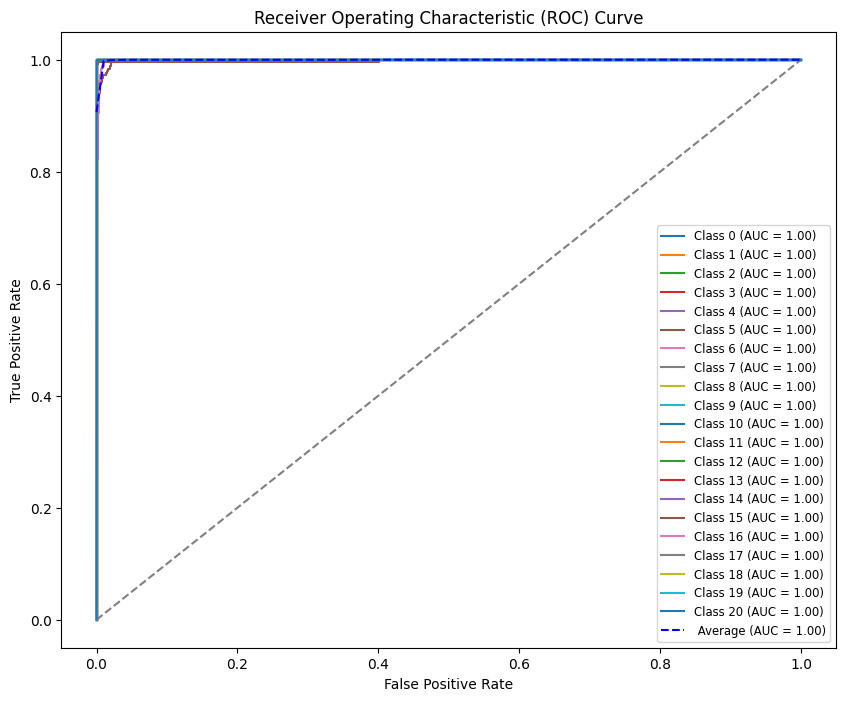

In [ ]:


plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

num_classes = len(set(all_test_labels))
classes_to_plot = range(0, num_classes, 1)
for i in classes_to_plot:
    fpr, tpr, _ = roc_curve(all_test_labels, [prob[i] for prob in all_test_probs], pos_label=i)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'Class {i} (AUC = {roc_auc:.2f})')

mean_fpr = np.linspace(0, 1, 100)
mean_tpr = np.zeros_like(mean_fpr)
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(all_test_labels, [prob[i] for prob in all_test_probs], pos_label=i)
    mean_tpr += np.interp(mean_fpr, fpr, tpr)
mean_tpr /= num_classes
roc_auc_macro = auc(mean_fpr, mean_tpr)
plt.plot(mean_fpr, mean_tpr, color='blue', linestyle='--', label=f' Average (AUC = {roc_auc_macro:.2f})')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right', fontsize='small')  # Adjust legend size
plt.show()

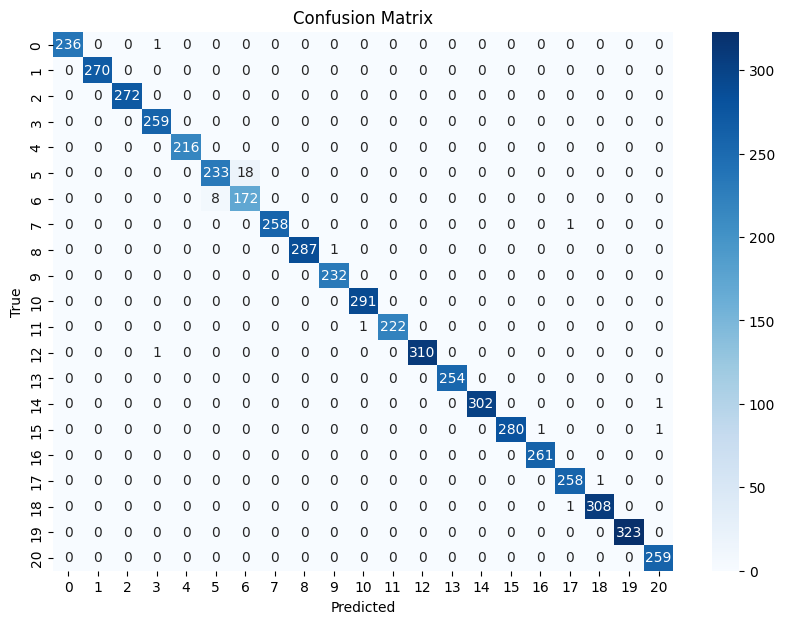

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       237
           1       1.00      1.00      1.00       270
           2       1.00      1.00      1.00       272
           3       0.99      1.00      1.00       259
           4       1.00      1.00      1.00       216
           5       0.97      0.93      0.95       251
           6       0.91      0.96      0.93       180
           7       1.00      1.00      1.00       259
           8       1.00      1.00      1.00       288
           9       1.00      1.00      1.00       232
          10       1.00      1.00      1.00       291
          11       1.00      1.00      1.00       223
          12       1.00      1.00      1.00       311
          13       1.00      1.00      1.00       254
          14       1.00      1.00      1.00       303
          15       1.00      0.99      1.00       282
          16       1.00      1.00      1.00       261
   

In [ ]:
conf_matrix = confusion_matrix(all_test_labels, all_test_predictions)

plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.arange(num_classes), yticklabels=np.arange(num_classes))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

class_report = classification_report(all_test_labels, all_test_predictions)
print("Classification Report:\n", class_report)

#test the model

In [ ]:
!pip install gdown

In [ ]:
!gdown --id 1Ib7om1T10b7I4HamaJuSZFcvtT5ihUUe

In [7]:
model = EfficientNet.from_pretrained('efficientnet-b7')
num_classes = 21
model._fc = nn.Linear(model._fc.in_features, num_classes)
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

Downloading: "https://github.com/lukemelas/EfficientNet-PyTorch/releases/download/1.0/efficientnet-b7-dcc49843.pth" to /root/.cache/torch/hub/checkpoints/efficientnet-b7-dcc49843.pth
100%|██████████| 254M/254M [00:01<00:00, 245MB/s]


Loaded pretrained weights for efficientnet-b7


<ipython-input-7-c8f2975553db>:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pth'))


EfficientNet(
  (_conv_stem): Conv2dStaticSamePadding(
    3, 64, kernel_size=(3, 3), stride=(2, 2), bias=False
    (static_padding): ZeroPad2d((0, 1, 0, 1))
  )
  (_bn0): BatchNorm2d(64, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
  (_blocks): ModuleList(
    (0): MBConvBlock(
      (_depthwise_conv): Conv2dStaticSamePadding(
        64, 64, kernel_size=(3, 3), stride=[1, 1], groups=64, bias=False
        (static_padding): ZeroPad2d((1, 1, 1, 1))
      )
      (_bn1): BatchNorm2d(64, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
      (_se_reduce): Conv2dStaticSamePadding(
        64, 16, kernel_size=(1, 1), stride=(1, 1)
        (static_padding): Identity()
      )
      (_se_expand): Conv2dStaticSamePadding(
        16, 64, kernel_size=(1, 1), stride=(1, 1)
        (static_padding): Identity()
      )
      (_project_conv): Conv2dStaticSamePadding(
        64, 32, kernel_size=(1, 1), stride=(1, 1), bias=False
  

In [16]:
class_idx_to_name = {
    0: "Apple___Apple_scab",
    1: "Apple___Black_rot",
    2: "Apple___Cedar_apple_rust",
    3: "Apple___healthy",
    4: "Blueberry___healthy",
    5: "Grape___Black_rot",
    6: "Grape___healthy",
    7: "Orange___Haunglongbing_(Citrus_greening)",
    8: "Peach___Bacterial_spot",
    9: "Peach___healthy",
    10: "Pepper,_bell___Bacterial_spot",
    11: "Pepper,_bell___healthy",
    12: "Soybean___healthy",
    13: "Squash___Powdery_mildew",
    14: "Tomato___Bacterial_spot",
    15: "Tomato___Late_blight",
    16: "Tomato___Septoria_leaf_spot",
    17: "Tomato___Spider_mites Two-spotted_spider_mite",
    18: "Tomato___Target_Spot",
    19: "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    20: "Tomato___healthy",
}

In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

In [18]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

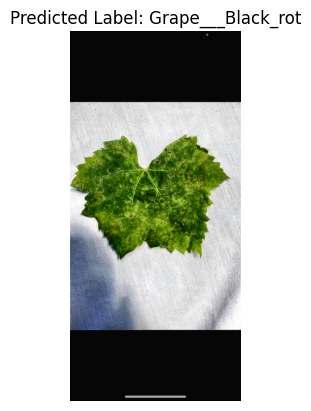

In [25]:
def apply_clahe(image):
    img_array = np.array(image)
    lab = cv2.cvtColor(img_array, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    img_output = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    return Image.fromarray(img_output)

def predict_and_show(image_path, model, transform, class_idx_to_name):
    image = Image.open(image_path).convert('RGB')

    image_clahe = apply_clahe(image)

    input_tensor = transform(image_clahe).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)
        _, predicted_class = torch.max(output, 1)
        predicted_label = class_idx_to_name[predicted_class.item()]  # Get class name

    plt.imshow(image_clahe)
    plt.title(f"Predicted Label: {predicted_label}")
    plt.axis('off')
    plt.show()

image_path = '/content/rot1.jpg'
predict_and_show(image_path, model, transform, class_idx_to_name)

